# PZ data challenge: results across all task sets

This notebook puts the results of the four task-set notebooks (`pz_challenge_taskset{1..4}_e2e.ipynb`) side by side. It covers all 16 configurations: 4 task sets × 2 sims × 2 depths. It reads the trained ensembles (the subtask 2 `.pkl` model files) those notebooks wrote to `OUT_DIR` (`outputs/znn` from scratch, `outputs/znn_pretrained_popcosmos` with pre-training, set by `PRETRAINING`; plus the method version `RUN` as a suffix) and trains nothing. All p(z)s are predicted here from those models with the current `znn` code, so the p(z) representation is the one `znn` produces now (a Gaussian with the mean and std of the predictions), whatever the run wrote as its own estimate files.

- **Part A, held-out scores** (the subtask 2 model files): each `.pkl` is reloaded and run on the same held-out split the task-set notebook used (`train_test_split` with `VAL_FRAC` and `SEED`). The results are scored with the challenge metrics and tiers. Predictions use the same photometric resampling as the submission (`N_SAMPLES` draws).
- **Part B, comparison with a baseline run**: Part A's held-out scores next to those of an earlier run, read from its held-out cache.
- **Part C, test-set p(z)** (optional, only with `PREDICT_TEST = True`): each model is run on its test file, as for the subtask 1 submission. The test redshifts are hidden, so this part only shows the predictions, i.e. the implied n(z) and the p(z) widths, set against the training redshift distribution.

The held-out and test-set predictions are cached in `CACHE_DIR`, outside `OUT_DIR` so they stay out of the submission tarball. Delete the cache to recompute, e.g. after changing how `znn` builds the p(z).

Run this from the repo root with the `qp` conda env as the kernel.

Plot conventions: **colour = depth** (blue 10yr, orange 1yr) and **line style = sim** (solid Cardinal, dashed Flagship).

## Configuration

In [1]:
import znn  # run from the repo root so this picks up the local source

TASKSETS = [1, 2, 3, 4]
SIMS = ["cardinal", "flagship"]
SCENARIOS = ["1yr", "10yr"]
TASKSET_NAMES = {
    1: "1: representative",
    2: "2: spec-selected",
    3: "3: spec + COSMOS",
    4: "4: spec + COSMOS, blended",
}

DATA_DIR = "../pz_data_challenge/scripts/public"  # as in the task-set notebooks
# Which run to read; must match the task-set notebooks: "popcosmos" (the pre-training shipped with znn) or None (from scratch). Each choice
# writes to its own directory, so runs with and without pre-training never overwrite each other.
PRETRAINING = "popcosmos"
# Method version, appended to OUT_DIR so runs of different versions never overwrite each other ("" for none):
# the RUN of the task-set notebooks ("noisy_kfold", plus "_frombase" with FROM_BASE); the p(z)s are predicted here
RUN = "kfold_frombase"  # set by run_challenge.py
OUT_DIR = ("outputs/znn" if PRETRAINING is None else f"outputs/znn_pretrained_{PRETRAINING}") + (f"_{RUN}" if RUN else "")  # the submission files written by the task-set notebooks
CACHE_DIR = f"{OUT_DIR}_predictions"  # held-out (part A) and test-set (part C) predictions
# Part C, at the end: predict every model's test set (as for the subtask 1 file) and show the implied n(z). It
# takes about as long as the held-out predictions, so it only runs when True
PREDICT_TEST = False
PLOT_DIR = "plots"  # figures are saved here, prefixed with the run name so runs never overwrite each other

# the held-out split: must match the task-set notebooks
VAL_FRAC = 0.2
SEED = 42
# prediction: photometric noise draws per object (converged by 50 on Cardinal Y1) and their seed
N_SAMPLES = 50
NOISE_SEED = 42

I0000 00:00:1793269824.967289 1558242 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import itertools
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qp
from qp.metrics.pit import PIT
from sklearn.model_selection import train_test_split

from pz_data_challenge import scoring

os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)

CONFIGS = list(itertools.product(TASKSETS, SIMS, SCENARIOS))
ZGRID = np.linspace(0, 3, 601)  # where p(z)s and the stacked n(z) are evaluated
COLORS = {"10yr": "#2a78d6", "1yr": "#eb6834"}
LINESTYLES = {"cardinal": "-", "flagship": "--"}
TRAIN_COLOR = "0.6"


def style(sim, scenario):
    return dict(color=COLORS[scenario], ls=LINESTYLES[sim], lw=1.5, label=f"{sim} {scenario}")


def save(fig, name):
    fig.savefig(os.path.join(PLOT_DIR, f"{os.path.basename(OUT_DIR)}_{name}.pdf"), bbox_inches="tight")


def path(kind, taskset, sim, scenario):
    if kind in ("training", "test"):
        return os.path.join(DATA_DIR, f"pz_challenge_taskset_{taskset}_{sim}_{kind}_{scenario}.hdf5")
    return os.path.join(OUT_DIR, f"pz_challenge_taskset_{taskset}_{sim}_{kind}_{scenario}.pkl")


missing = [p for c in CONFIGS if not os.path.exists(p := path("pz_model", *c))]
assert not missing, f"missing model files: {missing}"

## Reference redshifts

These are the same labels as in the task-set notebooks. Task sets 1 and 2 use `redshift`. Task sets 3 and 4 use `redshift` for spectroscopically selected objects and `redshift_manyband` for COSMOS-only objects, so scores on the COSMOS-only objects include the label noise.

In [3]:
SPEC_SURVEYS = ["DEEP2_LSST", "DESI_BGS", "DESI_ELG_LOP", "DESI_LRG", "VVDSf02", "zCOSMOS"]


def reference_redshifts(train):
    # Reference redshift per training object, and the held-out subsets to score (masks over train).
    z_spec = train["redshift"].to_numpy()
    if "COSMOS" not in train:  # task sets 1 and 2
        subsets = {"all": np.ones(len(train), dtype=bool)}
        if (train["mag_i_lsst"] < 23.5).all():
            return z_spec, subsets  # task set 1
        return z_spec, subsets | {"i > 23": train["mag_i_lsst"].to_numpy() > 23}  # task set 2

    is_spec = train[[c for c in SPEC_SURVEYS if c in train]].astype(bool).any(axis=1).to_numpy()
    is_cosmos_only = train["COSMOS"].astype(bool).to_numpy() & ~is_spec
    z_ref = np.where(is_cosmos_only, train["redshift_manyband"].to_numpy(), z_spec)
    assert np.isfinite(z_ref).all()
    return z_ref, {"all": np.ones(len(train), dtype=bool), "spec": is_spec, "COSMOS-only": is_cosmos_only}

# Part A: held-out scores

For each configuration the model file is reloaded and run on the held-out 20% of the training file. The model was trained on the other 80%, the same split as in the task-set notebooks. Each held-out set is scored on all of its objects and on the subsets the task-set notebook reported: task set 2 has `i > 23`, the faintest objects available, and task sets 3 and 4 have spec-selected and COSMOS-only.

Only task set 1 has a held-out set that is representative of its test set. For the other task sets these scores are **optimistic** for the test set.

In [4]:
def heldout_predictions(taskset, sim, scenario):
    # Held-out reference z, i-mag, subset masks, zmode, the p(z) mean and std, and the ensemble's p(z) (a qp
    # ensemble) under "pz". Cached in CACHE_DIR: the arrays in <stem>.npz, the p(z) in <stem>.hdf5.
    stem = os.path.join(CACHE_DIR, f"taskset_{taskset}_{sim}_{scenario}_pz")
    if os.path.exists(f"{stem}.npz") and os.path.exists(f"{stem}.hdf5"):
        return dict(np.load(f"{stem}.npz")) | {"pz": qp.read(f"{stem}.hdf5")}

    train = znn.read_catalog(path("training", taskset, sim, scenario))
    z_ref, subsets = reference_redshifts(train)
    _, idx_val = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
    val = train.iloc[idx_val]

    trained_models, features = znn.load_ensemble_file(path("pz_model", taskset, sim, scenario))
    errors = {col: f"{col}_err" for col, _ in features["bands"].values()}
    pz = znn.predict_from_catalog(
        trained_models, val, **features, errors=errors, n_samples=N_SAMPLES, rng=np.random.default_rng(NOISE_SEED)
    )
    out = {
        "z_ref": z_ref[idx_val],
        "mag_i": val["mag_i_lsst"].to_numpy(),
        "zmode": np.squeeze(pz.ancil["zmode"]),
        "mean": np.squeeze(pz.mean()),
        "std": np.squeeze(pz.std()),
        **{f"subset:{name}": mask[idx_val] for name, mask in subsets.items()},
    }
    np.savez(f"{stem}.npz", **out)
    pz.write_to(f"{stem}.hdf5")
    return out | {"pz": pz}


heldout = {}
for c in CONFIGS:
    print("held-out predictions:", *c)
    heldout[c] = heldout_predictions(*c)

held-out predictions: 1 cardinal 1yr
held-out predictions: 1 cardinal 10yr
held-out predictions: 1 flagship 1yr
held-out predictions: 1 flagship 10yr
held-out predictions: 2 cardinal 1yr
held-out predictions: 2 cardinal 10yr
held-out predictions: 2 flagship 1yr
held-out predictions: 2 flagship 10yr
held-out predictions: 3 cardinal 1yr
held-out predictions: 3 cardinal 10yr
held-out predictions: 3 flagship 1yr
held-out predictions: 3 flagship 10yr
held-out predictions: 4 cardinal 1yr
held-out predictions: 4 cardinal 10yr
held-out predictions: 4 flagship 1yr
held-out predictions: 4 flagship 10yr


In [5]:
def challenge_metrics(z_ref, zmode, pz):
    # The challenge's seven scored metrics, computed as in the task-set notebooks.
    dz = (zmode - z_ref) / (1 + z_ref)
    bias, _, scatter, _, abs_outlier_rate = znn.get_biweight_mean_sigma_outlier(dz)
    pit = PIT(pz, z_ref)
    return {
        "mean": bias,
        "std": scatter,
        "abs_outlier_rate": abs_outlier_rate,
        "ks": pit.evaluate_PIT_KS().statistic,
        "CvM": pit.evaluate_PIT_CvM().statistic,
        "ksamp": pit.evaluate_PIT_anderson_ksamp().statistic,
        # qp derives this from a spline fit to the PIT quantiles and it breaks down (negative or huge values)
        # when PIT piles up at 0 or 1; the challenge evaluator uses the same call, so it is what gets scored
        "outlier": pit.evaluate_PIT_outlier_rate(),
        # what it is meant to measure, computed directly (not scored)
        "pit_outlier_direct": np.mean((pit.pit_samps < 0.0001) | (pit.pit_samps > 0.9999)),
    }, pit.pit_samps


def tier_points(values):
    return {name: sum(lo <= float(values[name]) <= hi for lo, hi in ranges) for name, ranges in scoring.metric_dict.items()}


results, pits = {}, {}
for c, h in heldout.items():
    for key in [k for k in h if k.startswith("subset:")]:
        m = h[key]
        results[(*c, key.removeprefix("subset:"))], pits[(*c, key.removeprefix("subset:"))] = challenge_metrics(
            h["z_ref"][m], h["zmode"][m], h["pz"][np.flatnonzero(m)]
        )

table = pd.DataFrame(results).T[list(scoring.metric_dict) + ["pit_outlier_direct"]]
table.index.names = ["taskset", "sim", "scenario", "subset"]
points = pd.DataFrame({k: tier_points(v) for k, v in results.items()}).T
points.index.names = table.index.names
points["total"] = points.sum(axis=1)
N_MAX = sum(len(r) for r in scoring.metric_dict.values())
table.round(4)

/global/homes/j/jaimerz/envs/pzdc/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: Parameter `variant` has been introduced to replace `midrank`; `midrank` will be removed in SciPy 1.19.0. Specify `variant` to silence this warning. Note that the returned object will no longer be unpackable as a tuple, and `critical_values` will be omitted.
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)
/global/homes/j/jaimerz/envs/pzdc/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)


mean     std  abs_outlier_rate  \
taskset sim      scenario subset                                          
1       cardinal 1yr      all          0.0010  0.0177            0.0014   
                 10yr     all          0.0015  0.0112            0.0002   
        flagship 1yr      all          0.0011  0.0200            0.0011   
                 10yr     all         -0.0004  0.0125            0.0000   
2       cardinal 1yr      all          0.0041  0.0233            0.0082   
                          i > 23       0.0029  0.0391            0.0211   
                 10yr     all          0.0009  0.0146            0.0006   
                          i > 23      -0.0015  0.0188            0.0013   
        flagship 1yr      all          0.0004  0.0267            0.0072   
                          i > 23      -0.0046  0.0408            0.0173   
                 10yr     all         -0.0001  0.0151            0.0001   
                          i > 23      -0.0028  0.0187            0.0003   
3       cardinal 1yr      all          0.0059  0.0293            0.0506   
                          spec         0.0060  0.0192            0.0159   
                          COSMOS-only  0.0094  0.0899            0.1161   
                 10yr     all          0.0037  0.0192            0.0266   
                          spec         0.0032  0.0132            0.0009   
                          COSMOS-only  0.0084  0.0490            0.0710   
        flagship 1yr      all          0.0027  0.0393            0.0844   
                          spec         0.0024  0.0213            0.0030   
                          COSMOS-only  0.0089  0.0989            0.1586   
                 10yr     all          0.0011  0.0271            0.0430   
                          spec         0.0007  0.0144            0.0000   
                          COSMOS-only  0.0040  0.0529            0.0784   
4       cardinal 1yr      all          0.0044  0.0306            0.0546   
                          spec         0.0045  0.0204            0.0223   
                          COSMOS-only  0.0069  0.0868            0.1168   
                 10yr     all          0.0029  0.0200            0.0284   
                          spec         0.0029  0.0141            0.0063   
                          COSMOS-only  0.0037  0.0486            0.0685   
        flagship 1yr      all         -0.0004  0.0401            0.0842   
                          spec        -0.0001  0.0211            0.0046   
                          COSMOS-only  0.0028  0.0979            0.1546   
                 10yr     all          0.0035  0.0291            0.0507   
                          spec         0.0034  0.0162            0.0018   
                          COSMOS-only  0.0046  0.0565            0.0915   

                                            CvM       outlier      ks  \
taskset sim      scenario subset                                        
1       cardinal 1yr      all           24.2511  8.100000e-03  0.0567   
                 10yr     all           46.4526  1.000000e-03  0.0715   
        flagship 1yr      all           51.4636  5.900000e-03  0.0826   
                 10yr     all           51.8770  8.200000e-03  0.0731   
2       cardinal 1yr      all          108.8292  9.500000e-03  0.1080   
                          i > 23         7.2432  7.900000e-03  0.0511   
                 10yr     all           29.0054  1.600000e-03  0.0632   
                          i > 23         6.3308  8.000000e-04  0.0472   
        flagship 1yr      all           35.0499  1.050000e-02  0.0650   
                          i > 23        14.6945  8.000000e-03  0.0670   
                 10yr     all           50.9847  1.290000e-02  0.0747   
                          i > 23        24.4023  1.800000e-03  0.0892   
3       cardinal 1yr      all          185.7229  2.260000e-02  0.1430   
                          spec         168.6266  7.800000e-03  0.1651   
                      

### Points against the challenge tiers

There is one point per nested range a metric falls inside, so at most 3 per metric and 21 per configuration (`pz_data_challenge.scoring.metric_dict`). The table uses the `all` held-out subset.

A 0 under `outlier` is usually not a real failure. qp computes that metric from a spline fit to the PIT quantiles, which breaks down (negative or huge values) when PIT piles up at 0 or 1, so compare with `pit_outlier_direct` in the table above. The challenge evaluator makes the same call, so these are the points it would award.

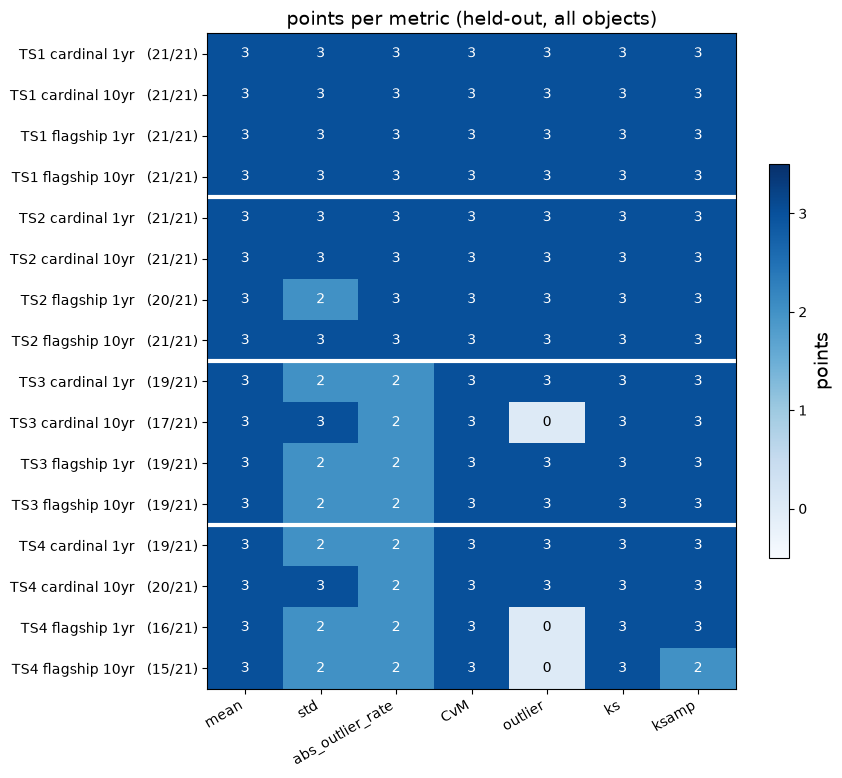

total points per task set (sum over its 4 configurations, held-out all):
taskset
1    84
2    83
3    74
4    70 
(out of 84 each)


In [6]:
pts_all = points.xs("all", level="subset")
labels = [f"TS{t} {s} {y}" for t, s, y in pts_all.index]
metrics = list(scoring.metric_dict)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(pts_all[metrics].to_numpy(), cmap="Blues", vmin=-0.5, vmax=3.5, aspect="auto")
for (i, j), v in np.ndenumerate(pts_all[metrics].to_numpy()):
    ax.text(j, i, int(v), ha="center", va="center", fontsize=10, color="white" if v >= 2 else "black")
ax.set_xticks(range(len(metrics)), metrics, rotation=30, ha="right")
ax.set_yticks(range(len(labels)), [f"{l}   ({t}/{N_MAX})" for l, t in zip(labels, pts_all["total"])])
for y in (3.5, 7.5, 11.5):
    ax.axhline(y, color="white", lw=3)
ax.set_title("points per metric (held-out, all objects)")
fig.colorbar(im, ax=ax, ticks=[0, 1, 2, 3], shrink=0.6, label="points")
fig.tight_layout()
save(fig, "points")
plt.show()

print("total points per task set (sum over its 4 configurations, held-out all):")
print(pts_all["total"].groupby(level="taskset").sum().to_string(), f"\n(out of {4 * N_MAX} each)")

### Subsets

These are the same metrics on the task-set-specific subsets. Task set 2's `i > 23` subset is the closest proxy for its faint test set. In task sets 3 and 4, `COSMOS-only` is the faint, test-like part, scored against noisy many-band labels.

In [7]:
sub = table.drop(index="all", level="subset")
sub_points = points.drop(index="all", level="subset")["total"].rename(f"points (/{N_MAX})")
pd.concat([sub, sub_points], axis=1).round(4)

mean     std  abs_outlier_rate  \
taskset sim      scenario subset                                          
2       cardinal 1yr      i > 23       0.0029  0.0391            0.0211   
                 10yr     i > 23      -0.0015  0.0188            0.0013   
        flagship 1yr      i > 23      -0.0046  0.0408            0.0173   
                 10yr     i > 23      -0.0028  0.0187            0.0003   
3       cardinal 1yr      spec         0.0060  0.0192            0.0159   
                          COSMOS-only  0.0094  0.0899            0.1161   
                 10yr     spec         0.0032  0.0132            0.0009   
                          COSMOS-only  0.0084  0.0490            0.0710   
        flagship 1yr      spec         0.0024  0.0213            0.0030   
                          COSMOS-only  0.0089  0.0989            0.1586   
                 10yr     spec         0.0007  0.0144            0.0000   
                          COSMOS-only  0.0040  0.0529            0.0784   
4       cardinal 1yr      spec         0.0045  0.0204            0.0223   
                          COSMOS-only  0.0069  0.0868            0.1168   
                 10yr     spec         0.0029  0.0141            0.0063   
                          COSMOS-only  0.0037  0.0486            0.0685   
        flagship 1yr      spec        -0.0001  0.0211            0.0046   
                          COSMOS-only  0.0028  0.0979            0.1546   
                 10yr     spec         0.0034  0.0162            0.0018   
                          COSMOS-only  0.0046  0.0565            0.0915   

                                            CvM       outlier      ks  \
taskset sim      scenario subset                                        
2       cardinal 1yr      i > 23         7.2432  7.900000e-03  0.0511   
                 10yr     i > 23         6.3308  8.000000e-04  0.0472   
        flagship 1yr      i > 23        14.6945  8.000000e-03  0.0670   
                 10yr     i > 23        24.4023  1.800000e-03  0.0892   
3       cardinal 1yr      spec         168.6266  7.800000e-03  0.1651   
                          COSMOS-only   35.4275 -8.853000e-01  0.1109   
                 10yr     spec          83.9709  1.900000e-03  0.1176   
                          COSMOS-only   59.4151  1.171781e+10  0.1381   
        flagship 1yr      spec          47.3191  1.420000e-02  0.1092   
                          COSMOS-only   75.1558 -2.855400e+00  0.1356   
                 10yr     spec          21.8319  3.540000e-02  0.0736   
                          COSMOS-only   76.5133  2.688010e+01  0.1334   
4       cardinal 1yr      spec         118.2032  9.400000e-03  0.1499   
                          COSMOS-only   31.7506 -2.132200e+00  0.1070   
                 10yr     spec          80.7521  1.610000e-02  0.1164   
                          COSMOS-only   39.6396  1.190600e+00  0.1210   
        flagship 1yr      spec          26.1764  2.390000e-02  0.0778   
                          COSMOS-only   59.1521 -3.585370e+01  0.1157   
                 10yr     spec         118.7730  1.250000e-01  0.1820   
                          COSMOS-only  113.1784 -6.733167e+02  0.1667   

                                          ksamp  pit_outlier_direct  \
taskset sim      scenario subset                                      
2       cardinal 1yr      i > 23        27.1070              0.0074   
                 10yr     i > 23        27.5966              0.0044   
        flagship 1yr      i > 23        63.1820              0.0079   
                 10yr     i > 23        97.4456              0.0056   
3       cardinal 1yr      spec         566.4960              0.0075   
                          COSMOS-only  172.4938              0.0520   
                 10yr     spec         274.7998              0.0075   
                          COSMOS-only  266.2569              0.0717   
        flagship 1yr      spec         217.4914              0.0175   
  

### PIT

PIT histograms on the `all` held-out subset. A flat histogram means the p(z) is calibrated. A U shape means it is too narrow, and a hump means it is too wide.

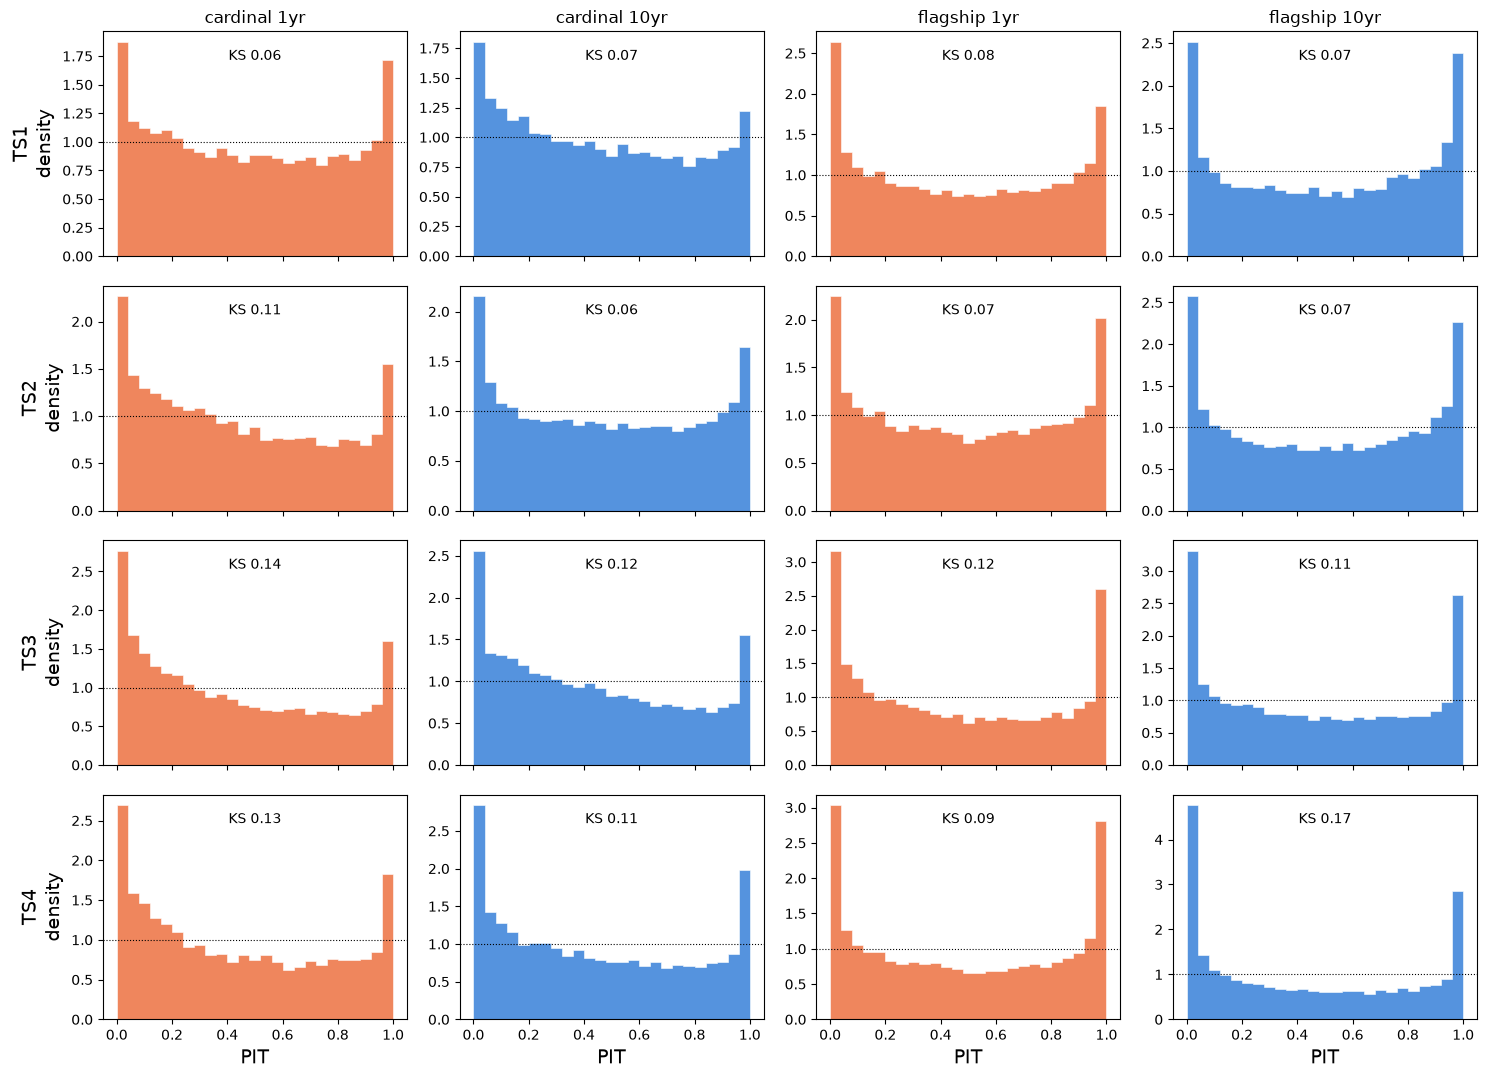

In [8]:
pit_bins = np.linspace(0, 1, 26)
fig, axes = plt.subplots(4, 4, figsize=(15, 11), sharex=True)
for row, taskset in enumerate(TASKSETS):
    for col, (sim, scenario) in enumerate(itertools.product(SIMS, SCENARIOS)):
        ax = axes[row, col]
        ax.hist(pits[(taskset, sim, scenario, "all")], pit_bins, density=True, color=COLORS[scenario],
                histtype="stepfilled", alpha=0.8, ec="white", lw=0.5)
        ax.axhline(1, color="k", lw=0.8, ls=":")
        ks = table.loc[(taskset, sim, scenario, "all"), "ks"]
        ax.text(0.5, 0.92, f"KS {ks:.2f}", transform=ax.transAxes, ha="center", va="top", fontsize=10)
        if row == 0:
            ax.set_title(f"{sim} {scenario}", fontsize=12)
        if col == 0:
            ax.set_ylabel(f"TS{taskset}\ndensity")
        if row == 3:
            ax.set_xlabel("PIT")
fig.tight_layout()
save(fig, "pit")
plt.show()

### Point estimates

`zmode` against the reference redshift on the `all` held-out subset (log-density 2D histogram). The dashed lines mark |Δz|/(1+z) = 0.2, the outlier threshold.

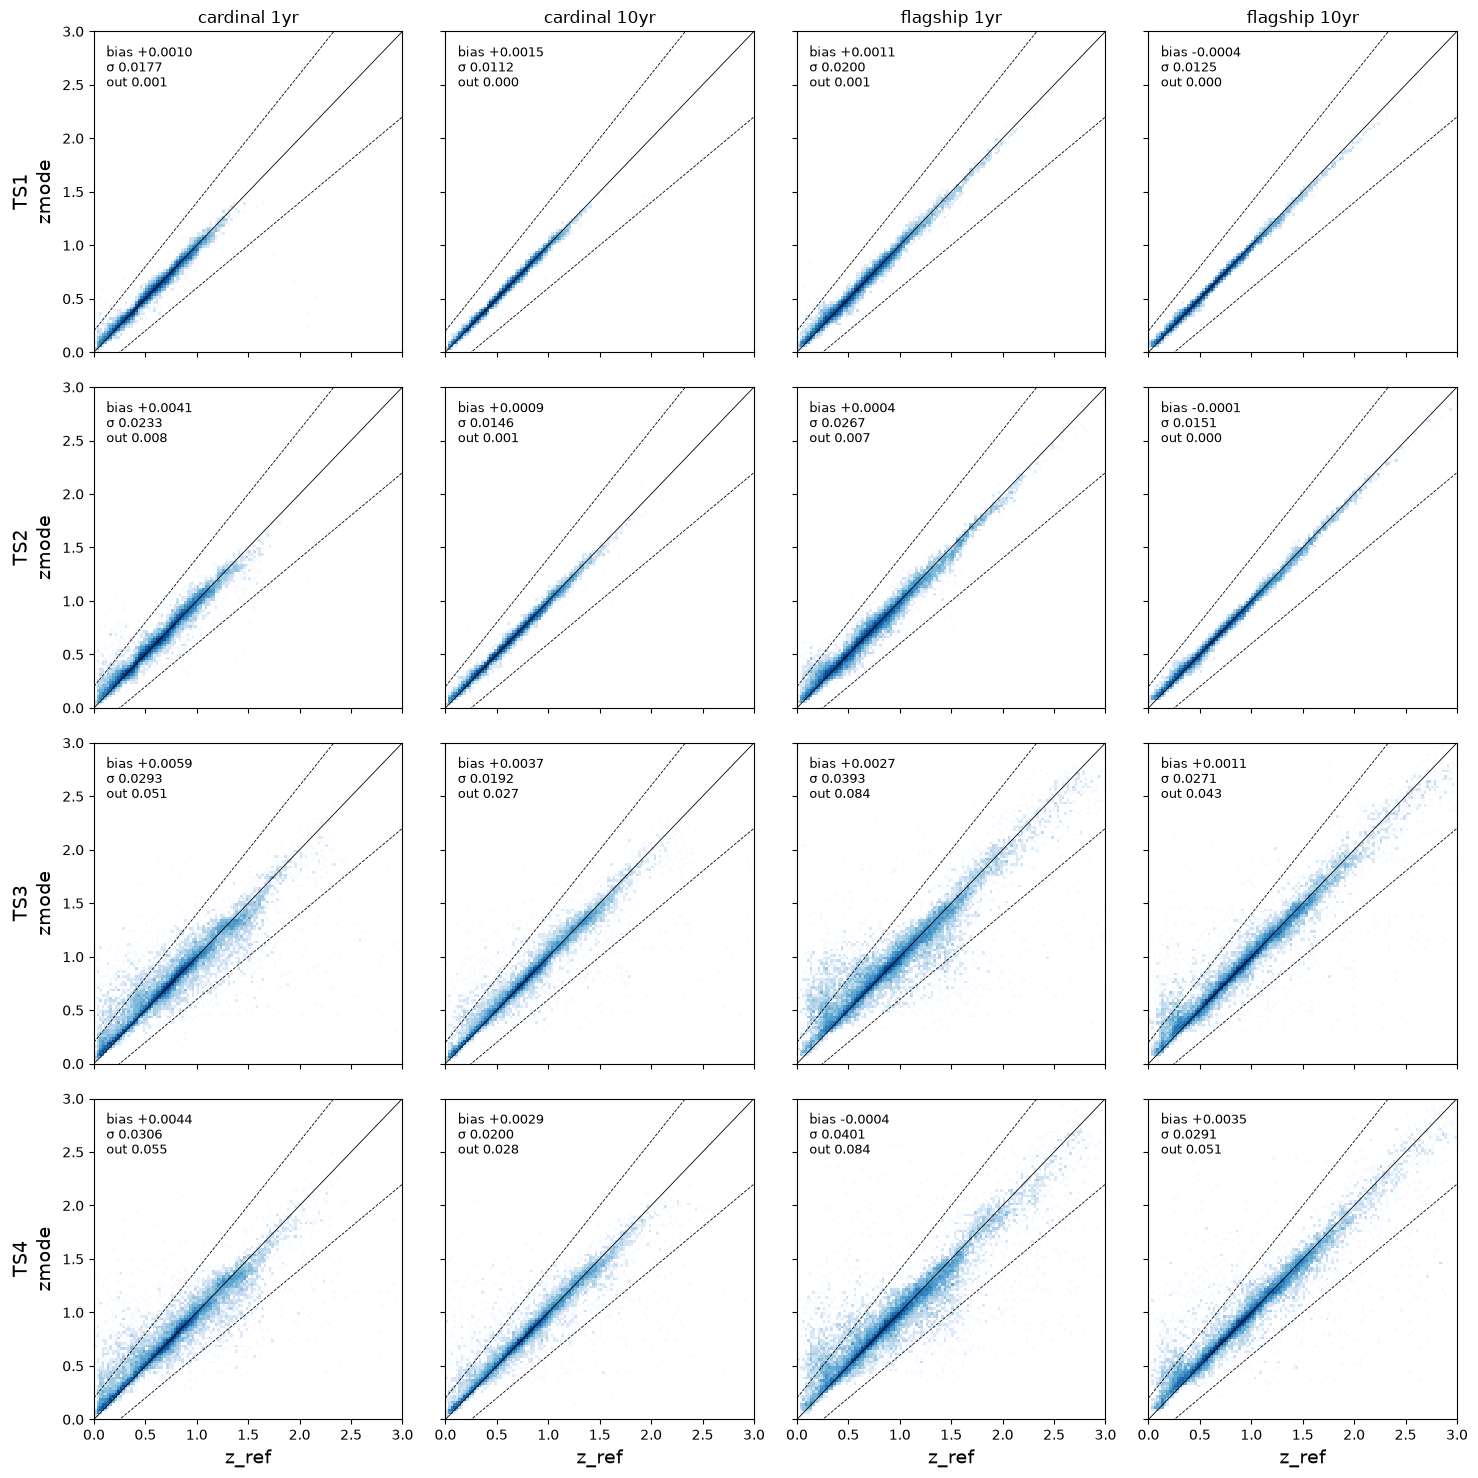

In [9]:
from matplotlib.colors import LogNorm

zb = np.linspace(0, 3, 121)
fig, axes = plt.subplots(4, 4, figsize=(15, 15), sharex=True, sharey=True)
for row, taskset in enumerate(TASKSETS):
    for col, (sim, scenario) in enumerate(itertools.product(SIMS, SCENARIOS)):
        ax = axes[row, col]
        h = heldout[(taskset, sim, scenario)]
        ax.hist2d(h["z_ref"], h["zmode"], bins=[zb, zb], cmap="Blues", norm=LogNorm(), rasterized=True)
        ax.plot(zb, zb, color="k", lw=0.6)
        for sgn in (-1, 1):
            ax.plot(zb, zb + sgn * 0.2 * (1 + zb), color="k", lw=0.6, ls="--")
        v = table.loc[(taskset, sim, scenario, "all")]
        ax.text(0.04, 0.96, f"bias {v['mean']:+.4f}\nσ {v['std']:.4f}\nout {v['abs_outlier_rate']:.3f}",
                transform=ax.transAxes, va="top", fontsize=9)
        ax.set_xlim(0, 3)
        ax.set_ylim(0, 3)
        if row == 0:
            ax.set_title(f"{sim} {scenario}", fontsize=12)
        if col == 0:
            ax.set_ylabel(f"TS{taskset}\nzmode")
        if row == 3:
            ax.set_xlabel("z_ref")
fig.tight_layout()
save(fig, "zphot_vs_zref")
plt.show()

# Part B: comparison with a baseline run

Part A's held-out scores next to those of an earlier run, read from that run's held-out cache. The baseline is the run before the noise realizations (no `RUN` suffix): every member trained on the catalogue photometry as given, on its own K-fold cut of the training objects, starting from its own pre-trained popcosmos member, and a Gaussian p(z) with the mean and std of the `N_SAMPLES` × members predictions. Its cache holds `z_ref`, `mag_i`, `mean`, `std` and the subset masks per configuration. Configurations missing from the cache are predicted from the baseline's model files (`BASELINE_OUT_DIR`) and added to it. It is scored here exactly as that version scored it, with the Gaussian mean as the point estimate.

Both runs use the same held-out split (`VAL_FRAC`, `SEED`), so they are scored on the same objects; this is checked.

In [10]:
# The baseline run: its OUT_DIR, with its model files, and its held-out cache (<BASELINE_OUT_DIR>_heldout:
# z_ref, mag_i, mean, std and the subset masks per configuration). A configuration missing from the cache
# (e.g. on a machine where the baseline was never scored) is predicted from its model file and added to it.
BASELINE_OUT_DIR = "outputs/znn_pretrained_popcosmos"
BASELINE_LABEL = "baseline"
NEW_LABEL = RUN or "new"
BASELINE_CACHE = f"{BASELINE_OUT_DIR}_heldout"
os.makedirs(BASELINE_CACHE, exist_ok=True)


def baseline_heldout(taskset, sim, scenario):
    cache = os.path.join(BASELINE_CACHE, f"taskset_{taskset}_{sim}_{scenario}.npz")
    if os.path.exists(cache):
        return dict(np.load(cache))
    model_file = os.path.join(BASELINE_OUT_DIR, f"pz_challenge_taskset_{taskset}_{sim}_pz_model_{scenario}.pkl")
    assert os.path.exists(model_file), f"no baseline held-out cache or model file for {(taskset, sim, scenario)}: {model_file}"
    train = znn.read_catalog(path("training", taskset, sim, scenario))
    z_ref, subsets = reference_redshifts(train)
    _, idx_val = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
    val = train.iloc[idx_val]
    trained_models, features = znn.load_ensemble_file(model_file)
    errors = {col: f"{col}_err" for col, _ in features["bands"].values()}
    pz = znn.predict_from_catalog(
        trained_models, val, **features, errors=errors, n_samples=N_SAMPLES, rng=np.random.default_rng(NOISE_SEED))
    out = {
        "z_ref": z_ref[idx_val],
        "mag_i": val["mag_i_lsst"].to_numpy(),
        "mean": np.squeeze(pz.mean()),
        "std": np.squeeze(pz.std()),
        **{f"subset:{name}": mask[idx_val] for name, mask in subsets.items()},
    }
    np.savez(cache, **out)
    return out


base_results, base_pits = {}, {}
for c in CONFIGS:
    b = baseline_heldout(*c)
    assert np.array_equal(b["z_ref"], heldout[c]["z_ref"]), f"{c}: the baseline was scored on different held-out objects"
    for key in [k for k in b if k.startswith("subset:")]:
        m = b[key]
        pz = qp.Ensemble(qp.stats.norm, data={"loc": b["mean"][m, None], "scale": b["std"][m, None]})
        base_results[(*c, key.removeprefix("subset:"))], base_pits[(*c, key.removeprefix("subset:"))] = challenge_metrics(
            b["z_ref"][m], b["mean"][m], pz
        )

base_table = pd.DataFrame(base_results).T[table.columns]
base_table.index.names = table.index.names
base_points = pd.DataFrame({k: tier_points(v) for k, v in base_results.items()}).T
base_points.index.names = table.index.names
base_points["total"] = base_points.sum(axis=1)

# metrics side by side on the "all" subset, baseline then new for each metric
comparison = pd.concat({BASELINE_LABEL: base_table, NEW_LABEL: table}, axis=1).xs("all", level="subset")
comparison = comparison.swaplevel(axis=1)[[(m, r) for m in table.columns for r in (BASELINE_LABEL, NEW_LABEL)]]
comparison.round(4)

/global/homes/j/jaimerz/envs/pzdc/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: Parameter `variant` has been introduced to replace `midrank`; `midrank` will be removed in SciPy 1.19.0. Specify `variant` to silence this warning. Note that the returned object will no longer be unpackable as a tuple, and `critical_values` will be omitted.
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)
/global/homes/j/jaimerz/envs/pzdc/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)


mean                     std                 \
                          baseline kfold_frombase baseline kfold_frombase   
taskset sim      scenario                                                   
1       cardinal 1yr        0.0018         0.0010   0.0178         0.0177   
                 10yr       0.0007         0.0015   0.0113         0.0112   
        flagship 1yr        0.0004         0.0011   0.0199         0.0200   
                 10yr      -0.0002        -0.0004   0.0117         0.0125   
2       cardinal 1yr        0.0038         0.0041   0.0233         0.0233   
                 10yr       0.0015         0.0009   0.0138         0.0146   
        flagship 1yr        0.0004         0.0004   0.0265         0.0267   
                 10yr       0.0002        -0.0001   0.0146         0.0151   
3       cardinal 1yr        0.0049         0.0059   0.0274         0.0293   
                 10yr       0.0034         0.0037   0.0187         0.0192   
        flagship 1yr        0.0006         0.0027   0.0390         0.0393   
                 10yr       0.0036         0.0011   0.0271         0.0271   
4       cardinal 1yr        0.0050         0.0044   0.0311         0.0306   
                 10yr       0.0023         0.0029   0.0191         0.0200   
        flagship 1yr        0.0029        -0.0004   0.0410         0.0401   
                 10yr       0.0005         0.0035   0.0283         0.0291   

                          abs_outlier_rate                      CvM  \
                                  baseline kfold_frombase  baseline   
taskset sim      scenario                                             
1       cardinal 1yr                0.0016         0.0014   60.0842   
                 10yr               0.0002         0.0002   33.3644   
        flagship 1yr                0.0012         0.0011   49.8812   
                 10yr               0.0000         0.0000   67.6429   
2       cardinal 1yr                0.0088         0.0082   94.1080   
                 10yr               0.0005         0.0006   52.8723   
        flagship 1yr                0.0070         0.0072   50.1886   
                 10yr               0.0001         0.0001   73.6012   
3       cardinal 1yr                0.0530         0.0506  197.6953   
                 10yr               0.0264         0.0266  141.7389   
        flagship 1yr                0.0848         0.0844  118.8228   
                 10yr               0.0438         0.0430  280.7299   
4       cardinal 1yr                0.0544         0.0546  219.4939   
                 10yr               0.0290         0.0284  133.0587   
        flagship 1yr                0.0872         0.0842  163.6820   
                 10yr               0.0506         0.0507  131.8562   

                                          outlier                      ks  \
                          kfold_frombase baseline kfold_frombase baseline   
taskset sim      scenario                                                   
1       cardinal 1yr             24.2511   0.0103         0.0081   0.0871   
                 10yr            46.4526   0.0025         0.0010   0.0667   
        flagship 1yr             51.4636   0.0093         0.0059   0.0766   
                 10yr            51.8770   0.0297         0.0082   0.0847   
2       cardinal 1yr            108.8292   0.0101         0.0095   0.1001   
                 10yr            29.0054   0.0033         0.0016   0.0782   
        flagship 1yr             35.0499   0.0180         0.0105   0.0773   
                 10yr            50.9847   0.0376         0.0129   0.0934   
3       cardinal 1yr            185.7229   0.0604         0.0226   0.1518   
                 10yr           134.1696 -50.7710         1.1442   0.1198   
        flagship 1yr            120.9323  -0.0696         0.1145   0.1207   
                 10yr            92.0156 -11.3357         0.1062   0.1920   
4       cardinal 1yr            140.6626   0.0804         0.0

In [11]:
# challenge points, per configuration and summed per task set ("all" subset)
pts = pd.DataFrame(
    {
        BASELINE_LABEL: base_points.xs("all", level="subset")["total"],
        NEW_LABEL: points.xs("all", level="subset")["total"],
    }
)
pts["change"] = pts[NEW_LABEL] - pts[BASELINE_LABEL]
print(f"points per configuration (out of {N_MAX}):")
display(pts)
print(f"points per task set (out of {4 * N_MAX}):")
display(pts.groupby(level="taskset").sum())

# every subset, as differences new - baseline: lower is better for |mean|, std, abs_outlier_rate, ks, CvM, ksamp
diff = table[list(scoring.metric_dict)] - base_table[list(scoring.metric_dict)]
diff["|mean|"] = table["mean"].abs() - base_table["mean"].abs()
diff["points"] = points["total"] - base_points["total"]
diff.round(4)

points per configuration (out of 21):


baseline  kfold_frombase  change
taskset sim      scenario                                  
1       cardinal 1yr             21              21       0
                 10yr            21              21       0
        flagship 1yr             21              21       0
                 10yr            21              21       0
2       cardinal 1yr             21              21       0
                 10yr            21              21       0
        flagship 1yr             20              20       0
                 10yr            21              21       0
3       cardinal 1yr             19              19       0
                 10yr            17              17       0
        flagship 1yr             16              19       3
                 10yr            14              19       5
4       cardinal 1yr             19              19       0
                 10yr            20              20       0
        flagship 1yr             19              16      -3
                 10yr            17              15      -2

points per task set (out of 84):


,baseline,kfold_frombase,change
taskset,,,
1,84,84,0
2,83,83,0
3,66,74,8
4,75,70,-5


mean     std  abs_outlier_rate  \
taskset sim      scenario subset                                          
1       cardinal 1yr      all         -0.0008 -0.0001           -0.0001   
                 10yr     all          0.0008 -0.0002           -0.0000   
        flagship 1yr      all          0.0007  0.0001           -0.0000   
                 10yr     all         -0.0003  0.0008            0.0000   
2       cardinal 1yr      all          0.0004 -0.0000           -0.0005   
                          i > 23      -0.0006  0.0005           -0.0010   
                 10yr     all         -0.0007  0.0008            0.0001   
                          i > 23      -0.0016  0.0003            0.0001   
        flagship 1yr      all          0.0000  0.0002            0.0003   
                          i > 23      -0.0013  0.0002            0.0009   
                 10yr     all         -0.0003  0.0004            0.0000   
                          i > 23      -0.0009  0.0001            0.0000   
3       cardinal 1yr      all          0.0009  0.0019           -0.0023   
                          spec         0.0011  0.0011           -0.0015   
                          COSMOS-only -0.0019 -0.0001           -0.0039   
                 10yr     all          0.0004  0.0005            0.0002   
                          spec         0.0003  0.0002           -0.0002   
                          COSMOS-only  0.0009  0.0011            0.0008   
        flagship 1yr      all          0.0021  0.0003           -0.0004   
                          spec         0.0022 -0.0001           -0.0005   
                          COSMOS-only  0.0027 -0.0009           -0.0004   
                 10yr     all         -0.0025 -0.0000           -0.0008   
                          spec        -0.0021 -0.0005           -0.0002   
                          COSMOS-only -0.0029  0.0014           -0.0014   
4       cardinal 1yr      all         -0.0006 -0.0006            0.0002   
                          spec        -0.0003  0.0001           -0.0002   
                          COSMOS-only -0.0026 -0.0003            0.0009   
                 10yr     all          0.0006  0.0009           -0.0006   
                          spec         0.0011  0.0007            0.0002   
                          COSMOS-only -0.0018  0.0010           -0.0021   
        flagship 1yr      all         -0.0033 -0.0009           -0.0030   
                          spec        -0.0024 -0.0011           -0.0004   
                          COSMOS-only -0.0060 -0.0019           -0.0054   
                 10yr     all          0.0030  0.0008            0.0001   
                          spec         0.0032  0.0007           -0.0002   
                          COSMOS-only  0.0025  0.0010            0.0003   

                                            CvM       outlier      ks  \
taskset sim      scenario subset                                        
1       cardinal 1yr      all          -35.8332 -2.200000e-03 -0.0304   
                 10yr     all           13.0881 -1.600000e-03  0.0047   
        flagship 1yr      all            1.5825 -3.400000e-03  0.0061   
                 10yr     all          -15.7659 -2.160000e-02 -0.0116   
2       cardinal 1yr      all           14.7212 -6.000000e-04  0.0079   
                          i > 23        -1.5862  1.200000e-03 -0.0079   
                 10yr     all          -23.8669 -1.700000e-03 -0.0150   
                          i > 23         3.8487 -3.000000e-04  0.0131   
        flagship 1yr      all          -15.1387 -7.500000e-03 -0.0122   
                          i > 23         3.4806 -1.000000e-04  0.0077   
                 10yr     all          -22.6166 -2.470000e-02 -0.0187   
                          i > 23         7.6829 -5.000000e-04  0.0130   
3       cardinal 1yr      all          -11.9724 -3.780000e-02 -0.0088   
                          spec          21.3766 -2.700000e-03  0.0064   
                      

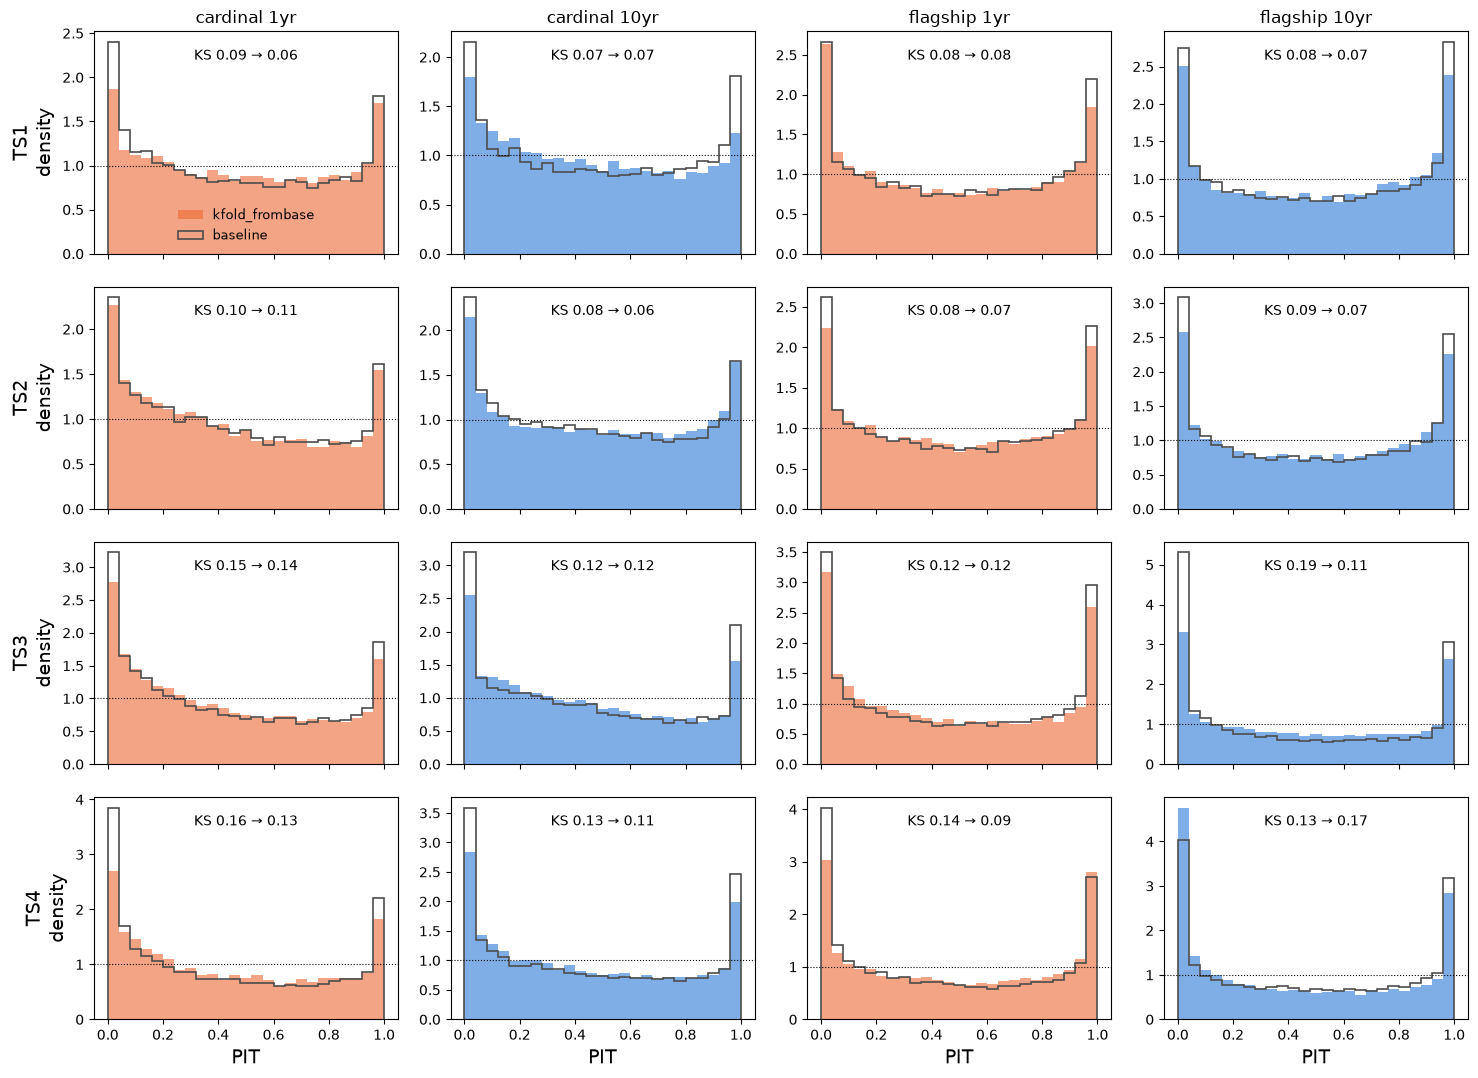

In [12]:
# PIT of the two runs on the "all" held-out subset: baseline outlined in grey, new filled
fig, axes = plt.subplots(4, 4, figsize=(15, 11), sharex=True)
for row, taskset in enumerate(TASKSETS):
    for col, (sim, scenario) in enumerate(itertools.product(SIMS, SCENARIOS)):
        ax = axes[row, col]
        key = (taskset, sim, scenario, "all")
        ax.hist(pits[key], pit_bins, density=True, color=COLORS[scenario], histtype="stepfilled", alpha=0.6,
                label=NEW_LABEL)
        ax.hist(base_pits[key], pit_bins, density=True, color="0.3", histtype="step", lw=1.2, label=BASELINE_LABEL)
        ax.axhline(1, color="k", lw=0.8, ls=":")
        ax.text(0.5, 0.92, f"KS {base_table.loc[key, 'ks']:.2f} → {table.loc[key, 'ks']:.2f}", transform=ax.transAxes,
                ha="center", va="top", fontsize=10)
        if row == 0:
            ax.set_title(f"{sim} {scenario}", fontsize=12)
        if col == 0:
            ax.set_ylabel(f"TS{taskset}\ndensity")
        if row == 3:
            ax.set_xlabel("PIT")
axes[0, 0].legend(fontsize=9, frameon=False, loc="lower center")
fig.tight_layout()
save(fig, "pit_vs_baseline")
plt.show()

# Appendix: what the CNN sees

The model does not take the band magnitudes as a list. Each magnitude (minus the reference i band) is spread over wavelength with its filter curve, and the result is averaged into `n_bins` equal-width wavelength bins. This gives a continuous curve (channel 0 of `X`), which is shown here for a few held-out galaxies across redshift.

- **Left:** the encoding of the catalogue photometry, drawn through the `n_bins` bin centres as in `znn.visualize_the_data`. The shaded band is the 16–84% range over `N_DRAWS` photometric resamplings, i.e. the noise the ensemble sees in training and at prediction time. The filter curves are in the strip on top. Bins with no observed band are 0 (and have 0 in the coverage channel).
- **Right:** the predicted p(z) for that galaxy from Part A (built from all its predictions), with the reference redshift as a dashed line.

I0000 00:00:1793269908.741914 1558242 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 79189 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:03:00.0, compute capability: 8.0
I0000 00:00:1793269908.745836 1558242 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 79189 MB memory:  -> device: 1, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:41:00.0, compute capability: 8.0
I0000 00:00:1793269908.749581 1558242 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:2 with 79189 MB memory:  -> device: 2, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:82:00.0, compute capability: 8.0
I0000 00:00:1793269908.757507 1558242 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:3 with 79189 MB memory:  -> device: 3, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:c1:00.0, compute capability: 8.0


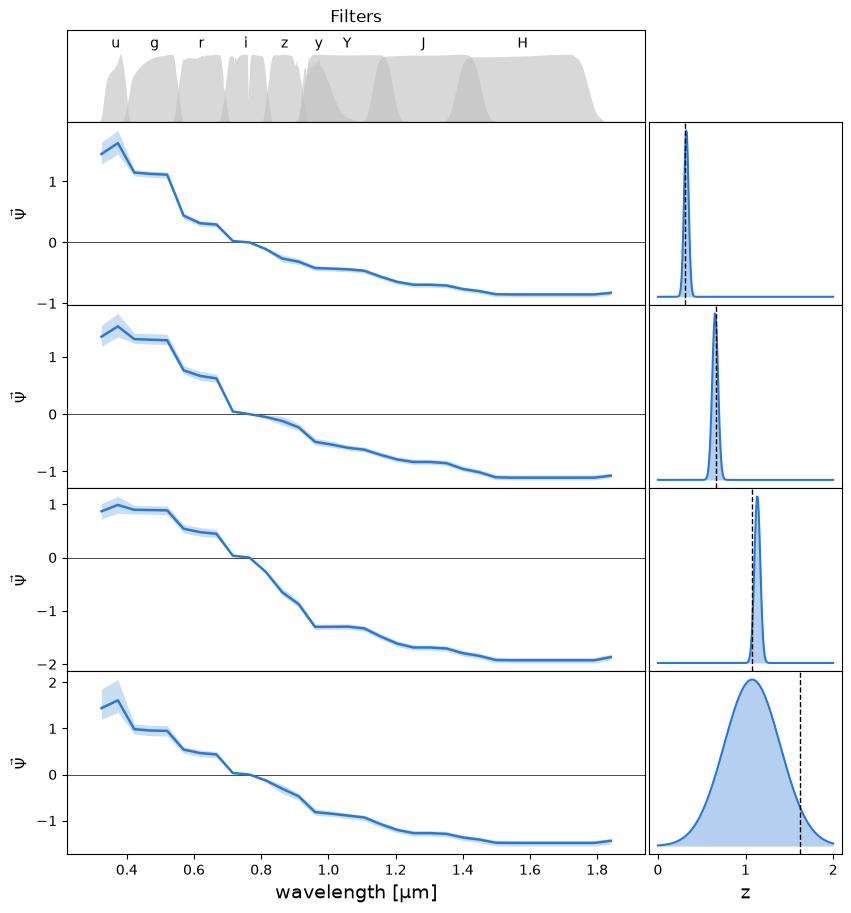

In [13]:
EXAMPLE = (1, "cardinal", "1yr")  # (task set, sim, depth); 1yr makes the photometric errors easier to see
Z_TARGETS = [0.3, 0.7, 1.1, 1.6]# 2.2]  # one galaxy picked near each reference redshift
IMAG_RANGE = (22.0, 23.5)  # faint enough for the errors to show
N_DRAWS = 200
ZGRID = np.linspace(0, 2, 201) 
rng = np.random.default_rng(1)

train = znn.read_catalog(path("training", *EXAMPLE))
_, idx_val = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
h = heldout[EXAMPLE]
_, features = znn.load_ensemble_file(path("pz_model", *EXAMPLE))
bands, curves, cfg = features["bands"], features["filter_curves"], features["config"]
errors = {col: f"{col}_err" for col, _ in bands.values()}

in_mag = (h["mag_i"] > IMAG_RANGE[0]) & (h["mag_i"] < IMAG_RANGE[1])
picks = [rng.choice(np.flatnonzero(in_mag & (np.abs(h["z_ref"] - zt) < 0.05))) for zt in Z_TARGETS]
gal = train.iloc[idx_val[picks]]

# wavelength bin centres, as catalog_to_XY builds them
lambda_common = np.linspace(min(c[:, 0].min() for c in curves.values()), max(c[:, 0].max() for c in curves.values()), cfg["n_lambda"])
lam_bins, _ = znn.make_lambda_bins(lambda_common, cfg["n_bins"])
lam_eff = {b: np.sum(c[:, 0] * c[:, 1]) / np.sum(c[:, 1]) for b, c in curves.items()}

X_obs, _ = znn.catalog_to_XY(gal, **features)
enc_draws = [znn.catalog_to_XY(znn.resample_photometry(gal, errors, rng), **features)[0][..., 0] for _ in range(N_DRAWS)]
enc_lo, enc_hi = np.percentile(enc_draws, [16, 84], axis=0)

ENC = "#2a78d6"
um = 1e-4  # filter curves are in Angstrom
fig, axes = plt.subplots(
    len(picks) + 1, 2, figsize=(10, 2.3 * len(picks) + 1.5), sharex="col",
    gridspec_kw=dict(height_ratios=[0.5] + [1] * len(picks), width_ratios=[3, 1], hspace=0.0, wspace=0.01),
)
for b, c in curves.items():
    axes[0, 0].fill_between(c[:, 0] * um, c[:, 1] / c[:, 1].max(), color="0.75", alpha=0.6, lw=0)
    axes[0, 0].text(lam_eff[b] * um, 1.05, b, ha="center", va="bottom", fontsize=10)
axes[0, 0].set_ylim(0, 1.35)
axes[0, 0].set_yticks([])
#axes[0, 0].set_ylabel("filters", fontsize=11)
axes[0, 1].axis("off")

for row, (k, j) in enumerate(zip(range(len(picks)), picks), start=1):
    ax = axes[row, 0]
    ax.axhline(0, color="k", lw=0.5)
    ax.fill_between(lam_bins * um, enc_lo[k], enc_hi[k], color=ENC, alpha=0.25, lw=0)
    ax.plot(lam_bins * um, X_obs[k, :, 0], color=ENC, lw=1.8)
    ax.set_ylabel(r"$\vec{\Psi}$", fontsize=11)
    #ax.text(0.99, 0.92, f"i = {h['mag_i'][j]:.2f}   z_ref = {h['z_ref'][j]:.2f}   zmode = {h['zmode'][j]:.2f}",
    #        transform=ax.transAxes, ha="right", va="top", fontsize=10)

    ax = axes[row, 1]
    pdf = np.squeeze(h["pz"][[j]].pdf(ZGRID))
    ax.fill_between(ZGRID, pdf, color=ENC, alpha=0.35, lw=0)
    ax.plot(ZGRID, pdf, color=ENC, lw=1.5)
    ax.axvline(h["z_ref"][j], color="k", ls="--", lw=1)
    ax.set_yticks([])
axes[-1, 0].set_xlabel("wavelength [μm]")
axes[-1, 1].set_xlabel("z")
axes[0, 0].set_title("Filters", fontsize=12)
save(fig, "encoding")
plt.show()

# Part C: test-set p(z)

Runs only with `PREDICT_TEST = True`.


Each model is run on its test file (`N_SAMPLES` noise draws, as for the submission), giving per-object Gaussian p(z)s with the mean and std of all `N_SAMPLES` × members predictions. They are cached in `CACHE_DIR`, and summarised by their `zmode` (the challenge's point estimate), mean and std, and matched to its test catalogue by `object_id` to pick up the i-band magnitude.

In [14]:
def test_predictions(taskset, sim, scenario):
    # The model's test-set p(z) (a qp ensemble), predicted as for the subtask 1 file. Cached in CACHE_DIR.
    cache = os.path.join(CACHE_DIR, f"test_taskset_{taskset}_{sim}_{scenario}_pz.hdf5")
    if os.path.exists(cache):
        return qp.read(cache)
    trained_models, features = znn.load_ensemble_file(path("pz_model", taskset, sim, scenario))
    test = znn.read_catalog(path("test", taskset, sim, scenario))
    errors = {col: f"{col}_err" for col, _ in features["bands"].values()}
    pz = znn.predict_from_catalog(
        trained_models, test, **features, errors=errors, n_samples=N_SAMPLES, rng=np.random.default_rng(NOISE_SEED),
        ids=test["object_id"].to_numpy(),
    )
    pz.write_to(cache)
    return pz


def read_estimate(taskset, sim, scenario):
    # Per-object summaries of the test-set p(z), and the stacked n(z) (mean p(z)) on ZGRID.
    pz = test_predictions(taskset, sim, scenario)
    est = pd.DataFrame(
        {
            "object_id": np.squeeze(pz.ancil["object_id"]),
            "zmode": np.squeeze(pz.ancil["zmode"]),
            "mean": np.squeeze(pz.mean()),
            "std": np.squeeze(pz.std()),
        }
    )
    test = znn.read_catalog(path("test", taskset, sim, scenario), columns=["object_id", "mag_i_lsst"])
    est = est.merge(test, on="object_id", how="left", validate="one_to_one")
    assert est["mag_i_lsst"].notna().all()
    return est, pz.pdf(ZGRID).mean(axis=0)


if PREDICT_TEST:
    estimates, stacked_nz, train_z = {}, {}, {}
    for c in CONFIGS:
        print("test-set predictions:", *c)
        estimates[c], stacked_nz[c] = read_estimate(*c)
        train = znn.read_catalog(path("training", *c))
        train_z[c], _ = reference_redshifts(train)

    summary = pd.DataFrame(
        {
            c: {
                "N test": len(e),
                "median zmode": e["zmode"].median(),
                "median σ": e["std"].median(),
                "median σ/(1+z)": (e["std"] / (1 + e["zmode"])).median(),
                "frac z < 0": (e["zmode"] < 0).mean(),
                "median i (test)": e["mag_i_lsst"].median(),
            }
            for c, e in estimates.items()
        }
    ).T
    summary.index.names = ["taskset", "sim", "scenario"]
    display(summary.round(4))


### Implied n(z) of the test set

The stacked test-set p(z) (the mean of the per-object p(z)s) against the training reference redshifts (grey, 10yr file). Task set 1 should agree with training. For task sets 2–4 the test set is fainter than the training set, so any difference between the two shows how far the model has to extrapolate.

In [15]:
if PREDICT_TEST:
    fig, axes = plt.subplots(2, 4, figsize=(16, 6.5), sharex=True, sharey=True)
    for col, taskset in enumerate(TASKSETS):
        for row, sim in enumerate(SIMS):
            ax = axes[row, col]
            ax.hist(train_z[(taskset, sim, "10yr")], bins=np.linspace(0, 3, 61), density=True,
                    histtype="stepfilled", color=TRAIN_COLOR, alpha=0.35, label="training z_ref")
            for scenario in SCENARIOS:
                ax.plot(ZGRID, stacked_nz[(taskset, sim, scenario)], **style(sim, scenario))
            ax.axvline(0, color="k", lw=0.5)
            if row == 0:
                ax.set_title(f"task set {TASKSET_NAMES[taskset]}", fontsize=12)
            if row == 1:
                ax.set_xlabel("z")
            if col == 0:
                ax.set_ylabel(f"{sim}\nn(z)")
            ax.legend(fontsize=9, frameon=False)
    fig.tight_layout()
    save(fig, "nz")
    plt.show()